# Evaluator: Similarity-Based Visibility

This notebook evaluates the outputs of `Visibility_similarity.py`. The focal independent variable, `similarity_share_ratio`, is the **fraction of eligible sender solutions recommended to each recipient** at each visibility event. Candidates are selected by increasing similarity (smaller Hamming distance) to that recipient's current configuration, with random tie-breaking; recipients adopt only a perceived improvement.

- `0.0`: search-apart benchmark (no recommendations).
- `0.05`: five recommendations per recipient when 100 senders are eligible.
- `1.0`: all eligible sender solutions are recommended (no similarity-based filtering).

**Interpretation:** Increasing `similarity_share_ratio` both enlarges the exposure pool and relaxes similarity selectivity. The horizontal axis therefore represents the **share recommended**, not a similarity score or an estimated causal effect of similarity alone. Figures and metrics concern the recipient crowd.


In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def format_axis(ax):
    """Keep the formatting of the provided evaluator."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [2]:
# =========================
# Experiment configuration — same as Visibility_similarity.py
# =========================
N = 18
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 600  # Documentation only; averages were already computed upstream.
solver_reset_num = 10  # Documentation only; resets were already averaged upstream.
search_iteration = 300
K_list = list(range(9, N))
visibility_extent = 1.0
similarity_share_ratio_list = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6,
                               0.7, 0.8, 0.9, 1.0]
# Include the entire sampled ratio grid, including search-apart and full exposure.
plot_ratio_list = similarity_share_ratio_list.copy()
plot_ratio_indices = [similarity_share_ratio_list.index(ratio) for ratio in plot_ratio_list]
ratio_ticks = np.round(np.arange(0.0, 1.01, 0.1), 1)
visibility_interval = 10

# Set this to the folder containing pickles from Visibility_similarity.py.
result_folder = "/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Similarity_based"

# Set to False to explore results without saving any figures.
save_figures = True
strict_loading = True  # Set False to view partial results from an unfinished run.

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (f'similarity_based_visibility_share_ratio_{similarity_share_ratio_list[0]}_interval_{visibility_interval}'
                    f'_breakthrough_rank_across_K_size_{agent_num}')

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_similarity_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Folder exists:', result_folder.exists())

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Similarity_based
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Similarity_based/visibility_similarity_figures
Example expected file: similarity_based_visibility_share_ratio_0.0_interval_10_breakthrough_rank_across_K_size_100
Folder exists: True


## 2. Load and validate the six outcome families

Files follow the similarity-based experiment's exact naming scheme, with **`similarity_share_ratio`** as the focal parameter and a fixed visibility interval:

`similarity_based_visibility_share_ratio_{ratio}_interval_{interval}_{DV}_across_K_size_{agent_num}`

The five scalar outcomes load as `(similarity share ratio, K)` arrays. The adoption-fitness trajectory loads as `(similarity share ratio, K, visibility event)`. The loader checks array shapes, preserves structurally undefined adoption quality as `NaN`, and reports missing files without shifting the grid.

In [3]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
expected_events = search_iteration // visibility_interval


def result_file(ratio, dv):
    filename = (f'similarity_based_visibility_share_ratio_{ratio}_interval_{visibility_interval}_'
                f'{dv}_across_K_size_{agent_num}')
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_similarity_results(strict=True):
    n_ratio = len(similarity_share_ratio_list)
    n_K = len(K_list)
    data = {dv: np.full((n_ratio, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_ratio, n_K, expected_events), np.nan)
    missing_files = []
    invalid_files = []

    for i, ratio in enumerate(similarity_share_ratio_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(ratio, dv)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, expected_events) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            data[dv][i] = values

    print(f'Files loaded: {n_ratio * 6 - len(missing_files) - len(invalid_files)} / {n_ratio * 6}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid similarity-based visibility results. Edit result_folder, agent_num, '
            'visibility_interval, the similarity-share-ratio grid, or set strict_loading=False '
            'for incomplete runs. First expected file: ' + str(result_file(similarity_share_ratio_list[0], 'breakthrough_rank'))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_visibility_similarity_results(strict=strict_loading)

Files loaded: 72 / 72
Array shapes: {'breakthrough_rank': (12, 9), 'breakthrough_fitness': (12, 9), 'pairwise_diversity': (12, 9), 'unique_solution_count': (12, 9), 'adopted_solution_fitness': (12, 9), 'adopted_solution_fitness_across_time': (12, 9, 30)}


In [4]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# The trajectory's final cumulative mean should match the scalar adoption-quality
# measure for each (similarity_share_ratio, K), up to floating-point differences.
last_trajectory = data[trajectory_dv][:, :, -1]
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, ratio in enumerate(similarity_share_ratio_list):
    for j, K in enumerate(K_list):
        row = {'similarity_share_ratio': ratio, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per similarity share ratio × K):')
# display(detailed_results.head(12).round(4))

breakthrough_rank             finite=108 / 108; outside expected range=0
breakthrough_fitness          finite=108 / 108; outside expected range=0
pairwise_diversity            finite=108 / 108; outside expected range=0
unique_solution_count         finite=108 / 108; outside expected range=0
adopted_solution_fitness      finite= 99 / 108; outside expected range=0
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per similarity share ratio × K):


## 3. Main results: similarity-based visibility

Each overall curve averages an outcome equally across **K = 9, ..., 17**. Companion figures show each K separately. All 12 sampled recommendation shares (**0.0, 0.05, 0.1, ..., 1.0**) appear in the figures; the axes use 0.1-spaced ticks for readability. At zero, no solutions are recommended; at one, every eligible sender solution is considered. The intermediate points select the most similar configurations separately for each recipient.

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Similarity_based/visibility_similarity_figures/Breakthrough_across_similarity_share_ratio.png


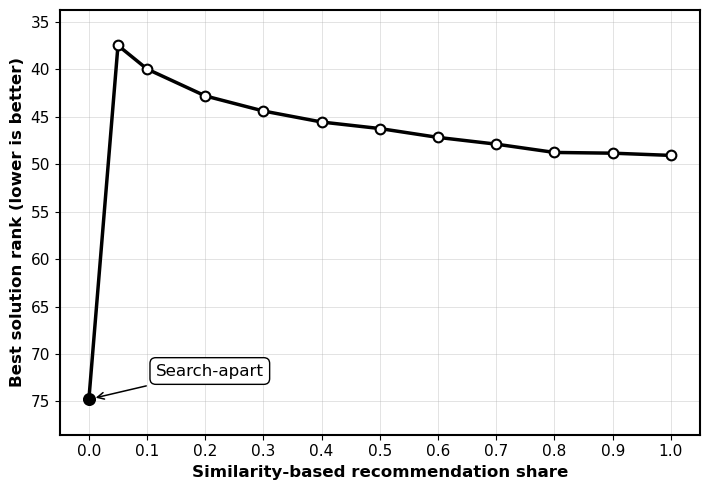

In [5]:
# =========================
# Best solution rank across similarity share ratio (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(plot_ratio_list)
y_rank = safe_nanmean(data["breakthrough_rank"][plot_ratio_indices], axis=1)

# Identify search-apart benchmark point
zero_idx = 0
zero_x, zero_y = x[zero_idx], y_rank[zero_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y_rank,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.margins(x=0.05, y=0.10)

# Highlight search-apart benchmark
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Search-apart annotation
# -------------------------
ax.annotate(
    "Search-apart",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.15, 0.15),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.invert_yaxis()  # Rank 1 is best; invert so a better rank is visually higher.
ax.set_xticks(ratio_ticks)

ax.set_xlabel(
    "Similarity-based recommendation share",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Best solution rank (lower is better)",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

if save_figures:
    output_png = figure_folder / "Breakthrough_across_similarity_share_ratio.png"

    plt.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )

    print("Saved:", output_png)

plt.show()

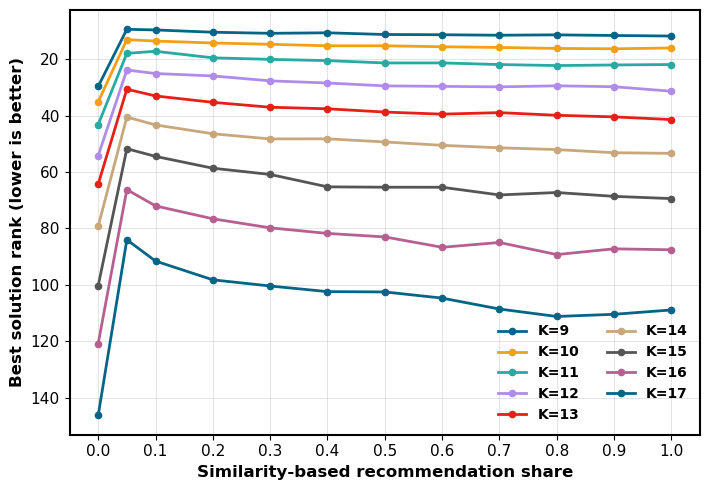

In [6]:
# Best solution rank across similarity share ratio (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['breakthrough_rank'][plot_ratio_indices, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xticks(ratio_ticks)
ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_by_K_across_similarity_share_ratio.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Similarity_based/visibility_similarity_figures/Pairwise_diversity_across_similarity_share_ratio.png


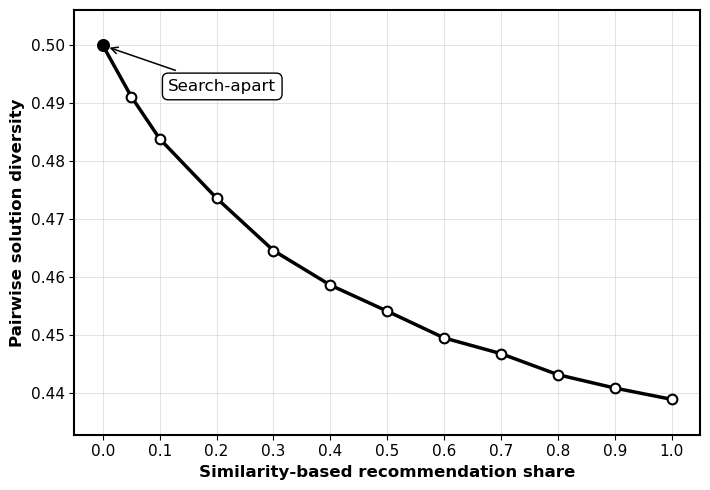

In [7]:
# =========================
# Pairwise diversity across similarity share ratio (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(plot_ratio_list)
y_diversity = safe_nanmean(data["pairwise_diversity"][plot_ratio_indices], axis=1)

# Identify search-apart benchmark point
zero_idx = 0
zero_x, zero_y = x[zero_idx], y_diversity[zero_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y_diversity,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.margins(x=0.05, y=0.10)

# Highlight search-apart benchmark
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Search-apart annotation
# -------------------------
ax.annotate(
    "Search-apart",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.15, 0.82),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.set_xticks(ratio_ticks)

ax.set_xlabel(
    "Similarity-based recommendation share",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Pairwise solution diversity",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

if save_figures:
    output_png = figure_folder / "Pairwise_diversity_across_similarity_share_ratio.png"

    plt.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )

    print("Saved:", output_png)

plt.show()

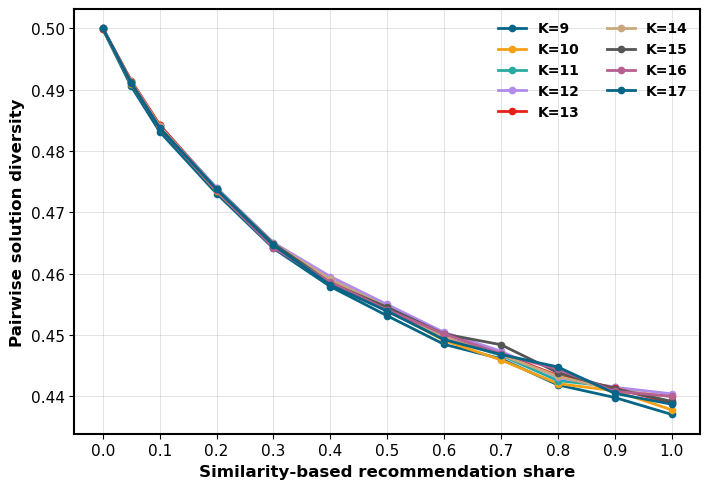

In [8]:
# Pairwise diversity across similarity share ratio (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['pairwise_diversity'][plot_ratio_indices, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(ratio_ticks)
ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_by_K_across_similarity_share_ratio.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

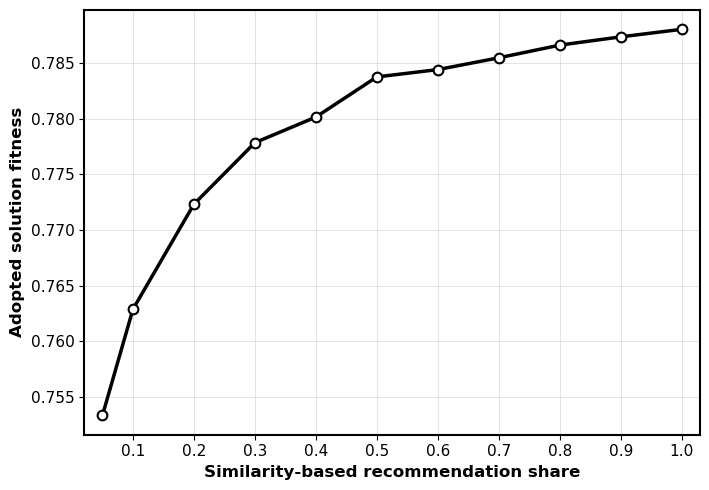

In [9]:
# Adopted solution fitness across similarity share ratio (average across K).
# Exclude similarity_share_ratio=0 because no sender solution is adopted.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)

y_adopted = safe_nanmean(data['adopted_solution_fitness'][plot_ratio_indices], axis=1)
valid = (x > 0) & np.isfinite(y_adopted)

ax.plot(x[valid], y_adopted[valid], marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)

ax.set_xticks(ratio_ticks[1:])
ax.set_xlim(x[valid].min() - 0.03, x[valid].max() + 0.03)
ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)

fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_quality_across_similarity_share_ratio.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

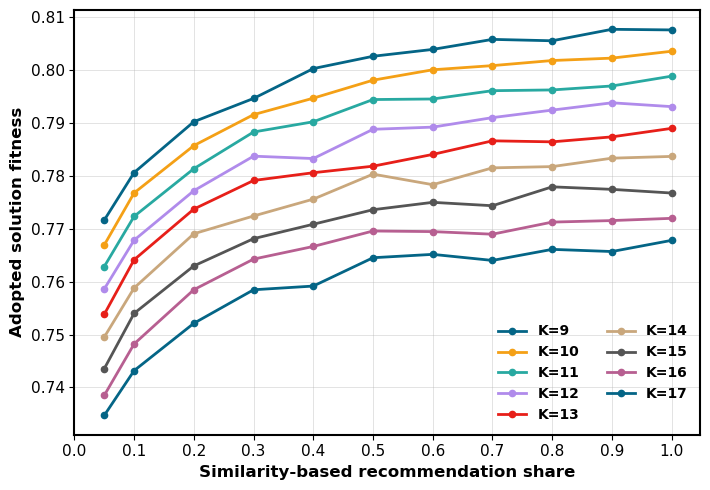

In [10]:
# Adopted solution fitness across similarity share ratio (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['adopted_solution_fitness'][plot_ratio_indices, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(ratio_ticks)
ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_similarity_share_ratio.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Additional outcomes

`breakthrough_fitness` is the highest final receiver-solution fitness within a repetition; `breakthrough_rank` is the best final receiver solution's rank in the landscape. These are related but distinct summary scales. `unique_solution_count` captures the number of distinct final receiver solutions, whereas **pairwise diversity** captures how different those solutions are, even when uniqueness coincides.

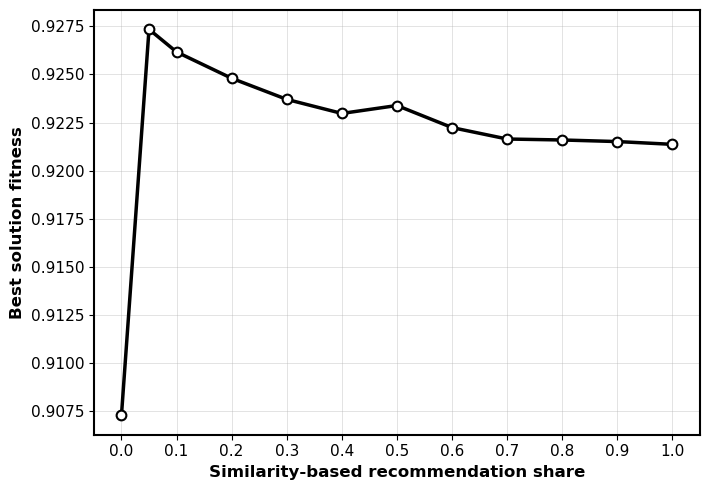

In [11]:
# Best solution fitness across similarity share ratio (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_fitness = safe_nanmean(data['breakthrough_fitness'][plot_ratio_indices], axis=1)
ax.plot(x, y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(ratio_ticks)
ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Best_solution_fitness_across_similarity_share_ratio.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

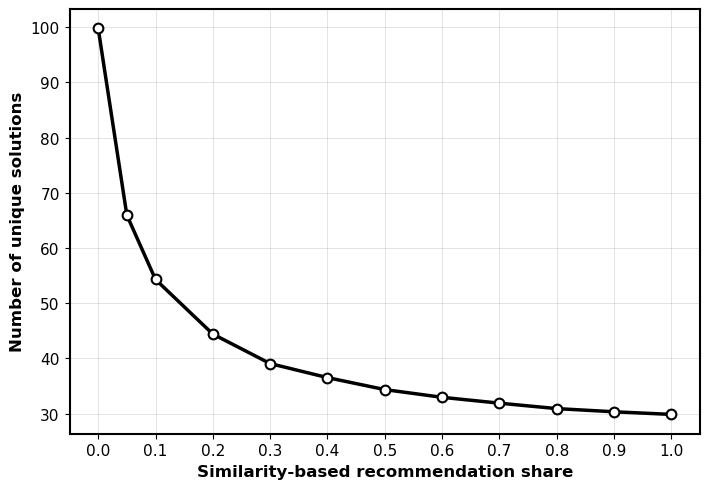

In [12]:
# Unique solution count across similarity share ratio (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_unique = safe_nanmean(data['unique_solution_count'][plot_ratio_indices], axis=1)
ax.plot(x, y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(ratio_ticks)
ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Unique_solution_count_across_similarity_share_ratio.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Adoption-quality trajectories across search time

Set `trajectory_similarity_share_ratio` to any sampled similarity recommendation share. The horizontal axis gives search periods (`10, 20, ..., 300` by default). Each ordinate is the **cumulative mean true fitness of adopted sender solutions through that visibility event** (rather than the fitness of all recipient solutions or the fitness of only that period's adoptions). At `similarity_share_ratio=0`, adoption quality is undefined and remains `NaN`. The first figure averages across K; the second plots each K separately.

In [13]:
trajectory_similarity_share_ratio = 0.9  # Change to any entry in similarity_share_ratio_list.
if trajectory_similarity_share_ratio not in similarity_share_ratio_list:
    raise ValueError('trajectory_similarity_share_ratio must appear in similarity_share_ratio_list.')
trajectory_index = similarity_share_ratio_list.index(trajectory_similarity_share_ratio)
trajectory_periods = (np.arange(1, expected_events + 1) * visibility_interval)
trajectory_by_K = data[trajectory_dv][trajectory_index]  # (K, visibility event)
print('Trajectory similarity share ratio:', trajectory_similarity_share_ratio)
print('Visibility events:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory similarity share ratio: 0.9
Visibility events: 30 | last search period: 300
Defined trajectory entries: 270 / 270


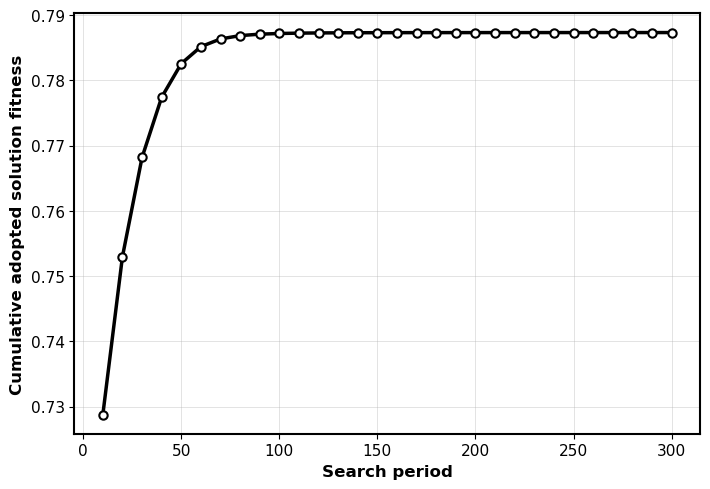

In [14]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_similarity_share_ratio_{trajectory_similarity_share_ratio:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

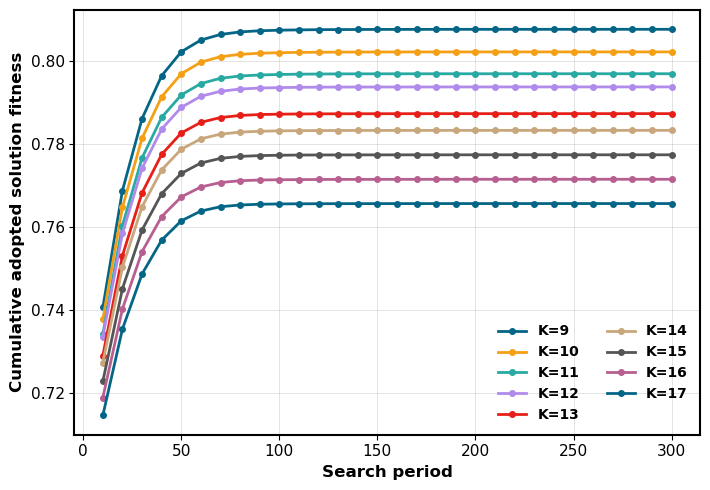

In [15]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_similarity_share_ratio_{trajectory_similarity_share_ratio:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Similarity recommendation share × landscape complexity

These heatmaps display the full sample of similarity recommendation shares (**0.0, 0.05, 0.1, ..., 1.0**) without pooling across `K`. `NaN` cells remain blank—especially for adoption quality at the search-apart benchmark. They help reveal whether an overall trend is stable across landscape complexity.

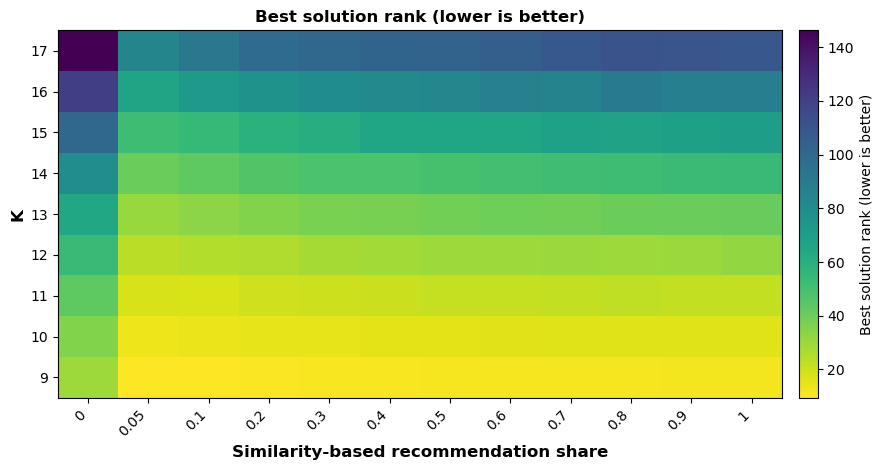

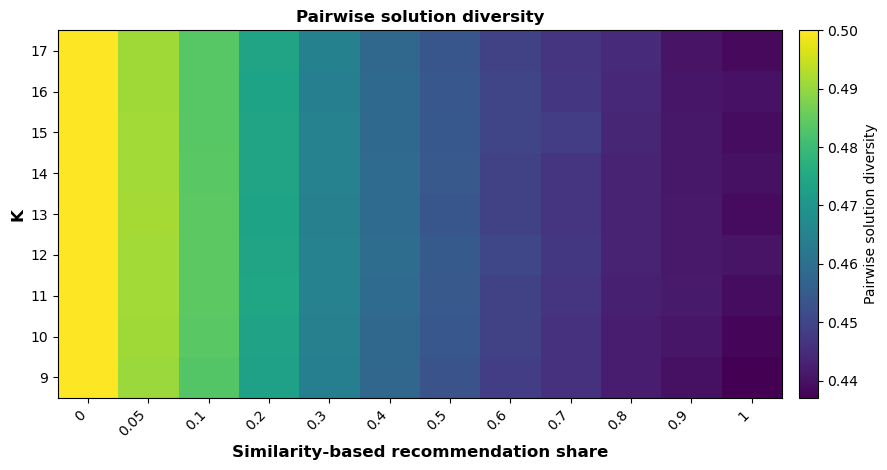

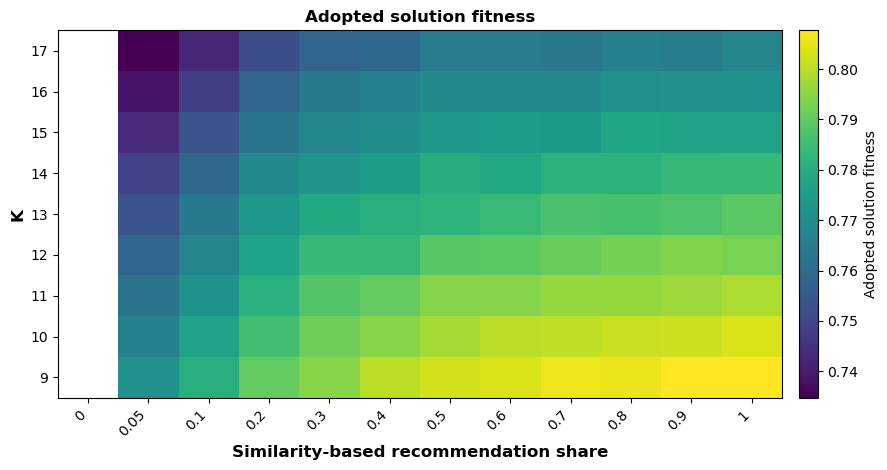

In [16]:
for dv, title, filename, cmap in [
    ('breakthrough_rank', 'Best solution rank (lower is better)', 'Best_solution_rank_heatmap_across_similarity_share_ratio_and_K.png', 'viridis_r'),
    ('pairwise_diversity', 'Pairwise solution diversity', 'Pairwise_diversity_heatmap_across_similarity_share_ratio_and_K.png', 'viridis'),
    ('adopted_solution_fitness', 'Adopted solution fitness', 'Adopted_solution_fitness_heatmap_across_similarity_share_ratio_and_K.png', 'viridis'),
]:
    values = np.ma.masked_invalid(data[dv][plot_ratio_indices].T)  # (K, displayed similarity share ratio)
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(plot_ratio_list)))
    ax.set_xticklabels([f'{ratio:g}' for ratio in plot_ratio_list], rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Similarity-based recommendation share', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    fig.tight_layout()
    # if save_figures:
    #     fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()